In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import glob
import json

sns.set_context("talk")
pd.options.display.max_columns = None

In [8]:
csv_files = glob.glob("../results/movebank/metrics/*.csv")
full_df = pd.concat((pd.read_csv(f) for f in csv_files), ignore_index=True)

species_metadata = pd.read_csv("../data/movebank/metadata/species_metadata.csv")
full_df = pd.merge(full_df, species_metadata, on=["species"])
full_df["movement"] = pd.Categorical(full_df["movement"], ['WALK', 'FLY', 'SWIM'])

full_df["final_sizes_raw"] = full_df["final_sizes"]
full_df["final_sizes"] = full_df["final_sizes_raw"].map(eval)
def count_scales(r):
    if r["final_sizes"] is not None:
        return len(r["final_sizes"]) + 1
    if r["num_stops"] > 0:
        return 1
    return 0
full_df["num_scales"] = full_df.apply(count_scales, axis=1)

df_10 = full_df[full_df["downsample_rate_minutes"] == 10]
df = full_df[full_df["downsample_rate_minutes"] == 60].copy()
# df = df_60.copy()


In [31]:
filtered = df[
    # (df["Stop Radius"] == 30) & 
    # (aggregated["Locomotion"] != "swim") &
    (df["days_spanned"] >= 60) &
    
    (df["num_scales"] >= 4) &
    (df["final_size_2"] <= 10000) & # weird outlier -- not sure which this is
    (df["median_speed"] <= 0.1) & # weird outlier -- arctic foxes
    (df["movement"] != "SWIM") &
    # (df["median_minutes_between_gps"] <= 70) &
    # (aggregated["Final Size 2"] >= 2000) & # weird outlier
    True
]

MOVEMENT_ORDER = ["WALK", "FLY"]
FAMILY_ORDER = filtered.family.unique()


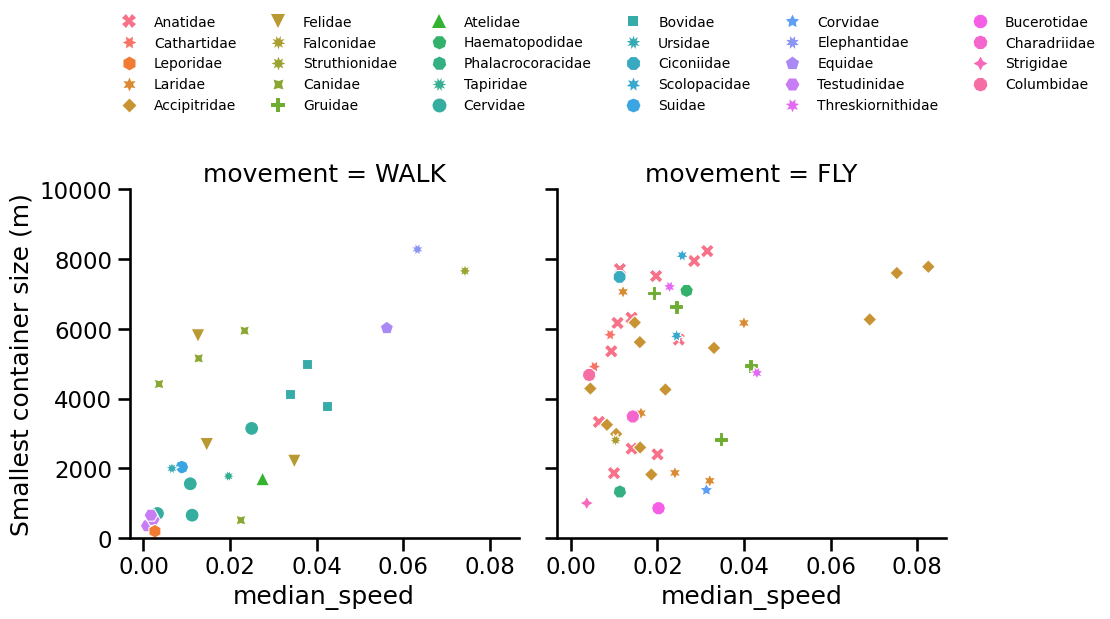

In [34]:
_aggregated = filtered.groupby(["species"]).agg(
    {
        "movement": "first",
        "median_body_length_cm": "first",
        "common_name": "first",
        "class": "first",
        "family": "first",
        "median_speed": "median",
        "num_scales": "mean",
        "final_size_2": "median",
    }
).reset_index()

p = sns.relplot(
    data=_aggregated,
    x="median_speed",
    y="final_size_2",
    hue="family",
    style="family",
    col="movement", s=100, legend=True,
    col_order=MOVEMENT_ORDER,
    hue_order=FAMILY_ORDER,
)

p.set(ylim=(0, 10000), ylabel="Smallest container size (m)")


sns.move_legend(
    p,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncols=6,
    title=None,
    frameon=False,
    fontsize=10,
)

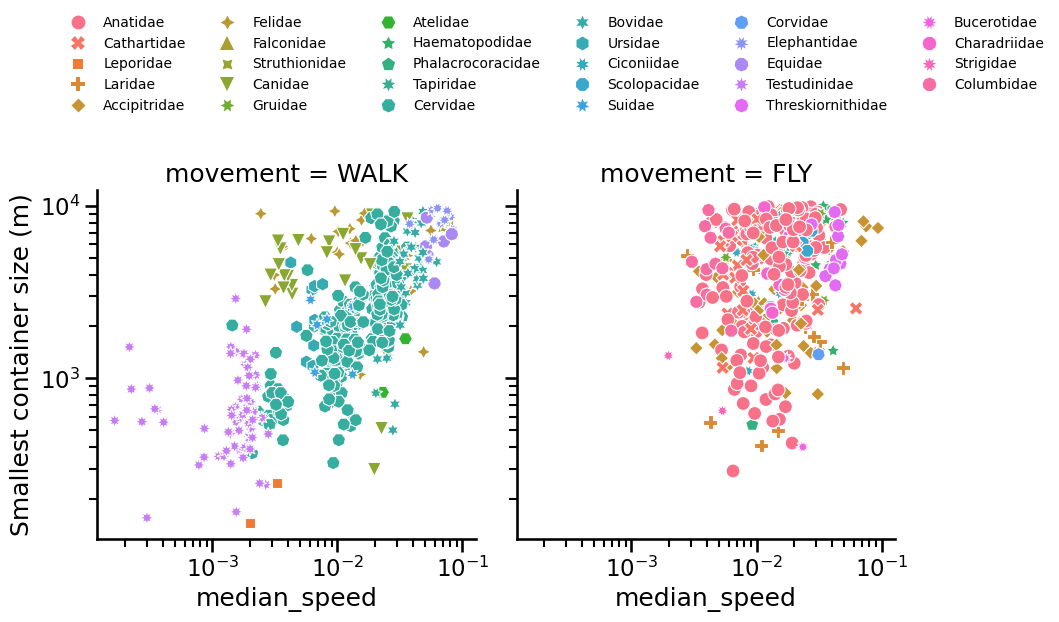

In [33]:
p = sns.relplot(
    data=filtered,
    x="median_speed",
    y="final_size_2",
    hue="family",
    style="family",
    col="movement", s=100, legend=True,
    col_order=MOVEMENT_ORDER,
    hue_order=FAMILY_ORDER,
)
p.set(yscale="log", xscale="log", ylabel="Smallest container size (m)")


sns.move_legend(
    p,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncols=6,
    title=None,
    frameon=False,
    fontsize=10,
)


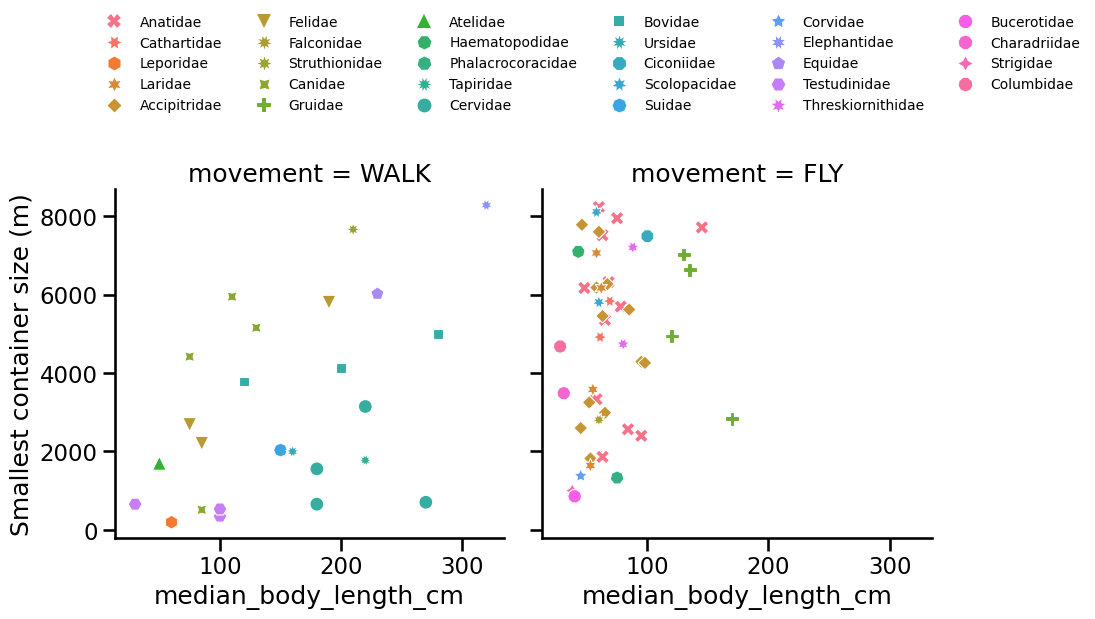

In [35]:
# _aggregated = filtered.groupby(["species", "movement", "median_body_length_cm", "common_name", "class", "family"]).agg(
#     {
#         "median_speed": "median",
#         "num_scales": "mean",
#         "final_size_2": "median",
#     }
# ).reset_index()

p = sns.relplot(
    data=_aggregated,
    x="median_body_length_cm",
    y="final_size_2",
    hue="family",
    style="family",
    col="movement", s=100, legend=True,
    col_order=MOVEMENT_ORDER,
    hue_order=FAMILY_ORDER,
)

p.set(ylabel="Smallest container size (m)")

sns.move_legend(
    p,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncols=6,
    title=None,
    frameon=False,
    fontsize=10,
)

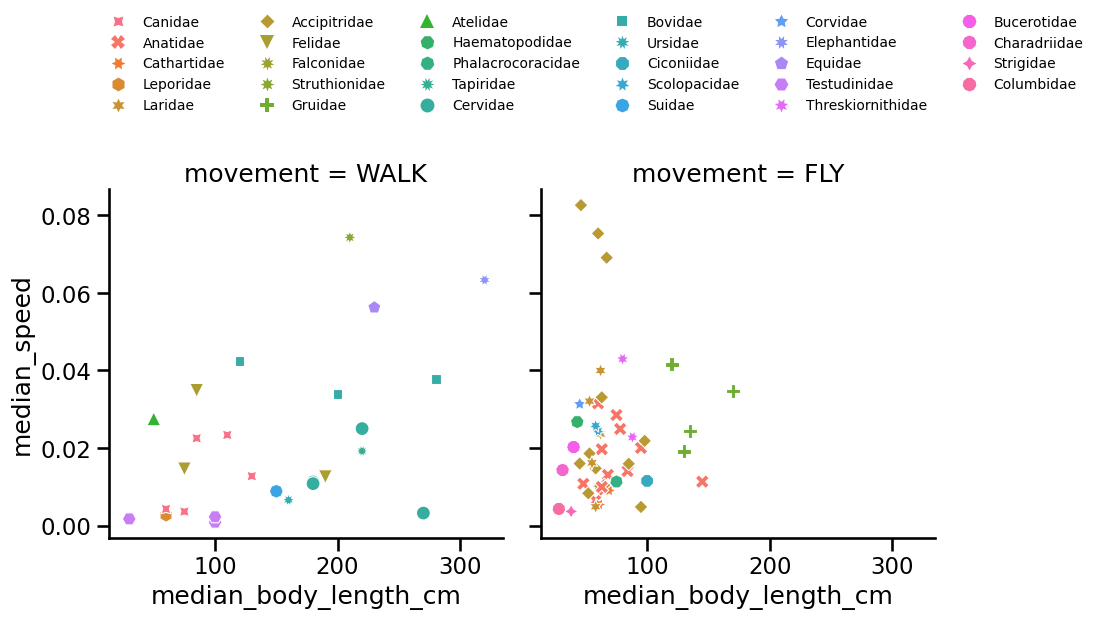

In [24]:
# _aggregated = filtered.groupby(["species", "movement", "median_body_length_cm", "common_name", "class", "family"]).agg(
#     {
#         "median_speed": "median",
#         "num_scales": "mean",
#         "final_size_2": "median",
#     }
# ).reset_index()

p = sns.relplot(
    data=_aggregated,
    x="median_body_length_cm",
    y="median_speed",
    hue="family",
    style="family",
    col="movement", s=100, legend=True,
    col_order=MOVEMENT_ORDER,
    hue_order=FAMILY_ORDER,
)

sns.move_legend(
    p,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncols=6,
    title=None,
    frameon=False,
    fontsize=10,
)